# HEXACO scores from joint rankings with TIRTRank

Use one joint ranking likelihood for each best–worst response to a
three-statement block.

## Model the rankings

Let $p$ be a respondent, $b$ a block and $j$ a statement in the block.
The trait measured by statement $j$ is $t(j)$. TIRTRank assigns the
statement a latent utility

$$
U_{pj}=\alpha_j+q_j a_j\theta_{p,t(j)}+\varepsilon_{pj},
\qquad
\varepsilon_{pj}\sim\mathcal N(0,v_j).
$$

The intercept $\alpha_j$ shifts the expected utility. The positive loading
$a_j$ controls its sensitivity to the trait score $\theta_{p,t(j)}$, and
$q_j\in\{-1,+1\}$ sets the direction. Conditional on scores and item
parameters, the statement residuals within the block are independent,
with variances $v_j$.

Write $Y_{pb}$ for the observed order, from most to least preferred. In a
triplet, $A>B>C$ means $A$ has higher utility than $B$ and $B$ has higher utility
than $C$:

$$
P(Y_{pb}=(A,B,C))
  =P(D_1>0,\ D_2>0),\qquad
D_1=U_{pA}-U_{pB},\quad D_2=U_{pB}-U_{pC}.
$$

The two differences are jointly normal. Their variances are $v_A+v_B$
and $v_B+v_C$, and their covariance is $-v_B$ because statement $B$ enters
with opposite signs. The model therefore uses the joint probability of
both inequalities.

The FC3 task records the best and worst statements. With three
statements, these choices identify the middle position as well.

### Set the score scale

Each trait has mean zero and SD one. Keying fixes its loading direction.
A reference intercept is fixed at zero and a reference residual variance
at 0.5 within each connected set of statements in this triplet design.
The remaining variances are estimated. [TIRTRank model and priors](../models/tirt_rank.md)

## Read the questionnaire and responses

The bundled FC3 data contain HEXACO responses from [Li et al. (2025)](https://doi.org/10.1177/10944281241229784).
Use the same random sample of 120 respondents and all 20 triplets in
the TIRT and TIRTRank examples. The design gives each statement's trait
and keying. A keying value of −1 means higher trait scores lower the
statement's expected appeal.

In [1]:
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example(
    "hexaco_fc3",
    model="TIRTRank",
    n_persons=120,
    random_seed=42,
)
example.data.design.head(3)

,block_id,position,statement_id,trait,keying
0,B1,1,i1,honestyhumility,-1
1,B1,2,i2,openness,-1
2,B1,3,i3,agreeableness,-1


Each response is stored as `[best, None, worst]`. For a triplet, the
middle statement is the one left over. TIRTRank therefore uses the
order of all three statements as one block-level response.

In [2]:
example.data.responses.frame.head(3)

,person_id,block_id,response
0,1,B1,"[3, None, 1]"
1,1,B2,"[3, None, 2]"
2,1,B3,"[1, None, 2]"


In [3]:
model = fc.Model()
model.add_fc(
    example.data.design,
    example.data.responses.frame,
    format="block_long",
    model="TIRTRank",
    response_format="mole",
)
model.prepare();

## Fit the model

Fit four chains with 1,800 warmup iterations and 1,200
retained draws per chain.

In [4]:
model.fit(draws=1200, tune=1800, chains=4);

## Diagnose the chains

Check R-hat, effective sample size and divergences before reading
the estimates.

In [5]:
import arviz as az
import numpy as np

posterior = model.idata.posterior.to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(model.idata.sample_stats.diverging.sum()))

Max R-hat: 1.017
Min bulk / tail ESS: 255 / 394
Divergences: 0


The density and rank panels compare chains for one person's
Honesty–Humility and Openness scores.

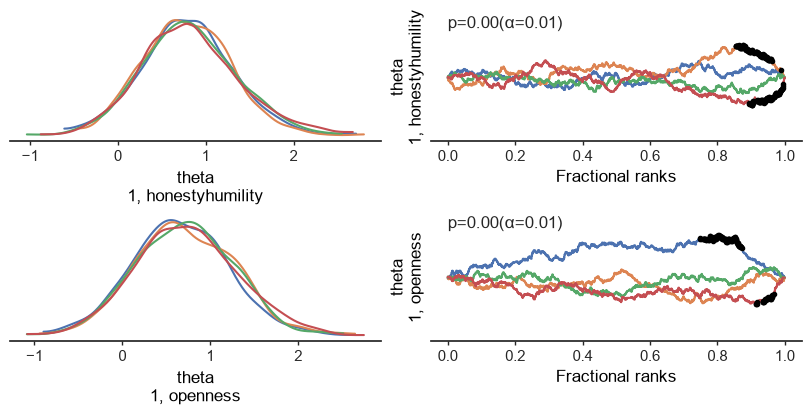

In [6]:
import arviz_plots as azp
import matplotlib.pyplot as plt

azp.plot_rank_dist(
    model.idata,
    var_names=["theta"],
    coords={
        "person": [int(model.idata.posterior.person.values[0])],
        "trait": ["honestyhumility", "openness"],
    },
    compact=False,
    backend="matplotlib",
    figure_kwargs={"figsize": (8, 4), "layout": "constrained"},
)
plt.show()

## Read the measurement estimates

The B1 table gives each statement's loading, utility intercept and
residual variance. The HDI columns give the limits of the 95% intervals.

In [7]:
model.coef(blocks=["B1"], kind="stats", round_to=2)

mean    sd  hdi95_lb  \
unit statement trait           parameter                                   
B1   i1        honestyhumility loading              1.11  0.31      0.57   
     i2        openness        loading              0.52  0.16      0.24   
     i3        agreeableness   loading              0.50  0.16      0.21   
     i1        honestyhumility statement_intercept  0.00   NaN       NaN   
     i2        openness        statement_intercept  0.65  0.17      0.35   
     i3        agreeableness   statement_intercept  1.17  0.24      0.75   
     i1        honestyhumility residual_variance    0.50   NaN       NaN   
     i2        openness        residual_variance    0.19  0.18      0.00   
     i3        agreeableness   residual_variance    1.21  0.49      0.33   

                                                    hdi95_ub  
unit statement trait           parameter                      
B1   i1        honestyhumility loading                  1.75  
     i2        openness        loading                  0.85  
     i3        agreeableness   loading                  0.82  
     i1        honestyhumility statement_intercept       NaN  
     i2        openness        statement_intercept      0.99  
     i3        agreeableness   statement_intercept      1.66  
     i1        honestyhumility residual_variance         NaN  
     i2        openness        residual_variance        0.53  
     i3        agreeableness   residual_variance        2.13

## Check the predicted rankings

Compare the observed proportions of the six possible orders in B1
with 200 sets of replicated responses. Crosses show observed proportions.
Dots and horizontal lines show predictive means and 95% predictive intervals.

In [8]:
predictions = model.posterior_predictive(draws=200, random_seed=45, include_probabilities=False)
view = fc.predictive_view(predictions, block="B1")

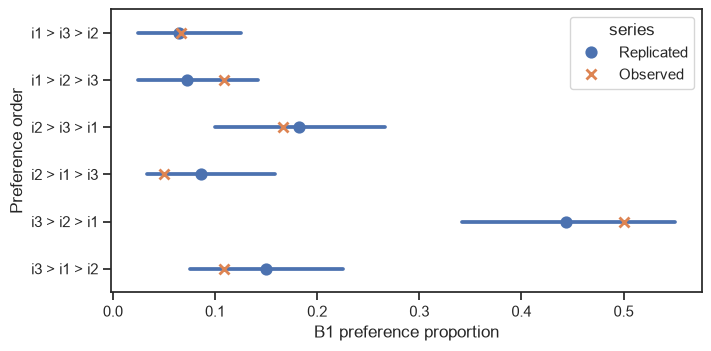

In [9]:
from itertools import permutations

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

statements = example.data.design.query("block_id == 'B1'").sort_values("position")
positions = statements.statement_id.tolist()
orders = [
    f"{best} > {middle} > {worst}"
    for best, worst in permutations(positions, 2)
    for middle in positions
    if middle not in (best, worst)
]
category = xr.DataArray(range(len(orders)), dims="order", coords={"order": orders})


def order_proportions(answers, series):
    share = (answers == category).mean("obs")
    return share.to_dataframe(name="proportion").reset_index().assign(series=series)


proportions = pd.concat(
    [
        order_proportions(view.posterior_predictive.response, "Replicated"),
        order_proportions(view.observed_data.response, "Observed"),
    ]
)
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
sns.pointplot(
    proportions,
    x="proportion",
    y="order",
    hue="series",
    order=orders,
    markers=["o", "x"],
    linestyles="none",
    errorbar=("pi", 95),
    ax=ax,
)
ax.set(xlabel="B1 preference proportion", ylabel="Preference order")
plt.show()

Half of the 120 respondents rank i3 first and i1 last in B1,
which gives the order i3 > i2 > i1.

## Read score precision

Empirical reliability compares variation across respondents with
posterior uncertainty about their scores.

In [10]:
model.reliability()["reliability"].to_series().round(3).to_frame("Reliability")

,Reliability
trait,
honestyhumility,0.674
openness,0.593
agreeableness,0.506
emotionality,0.598
conscientiousness,0.605
extraversion,0.716


The ridges show the posterior distributions of the first three
respondents' Honesty–Humility and Openness scores.

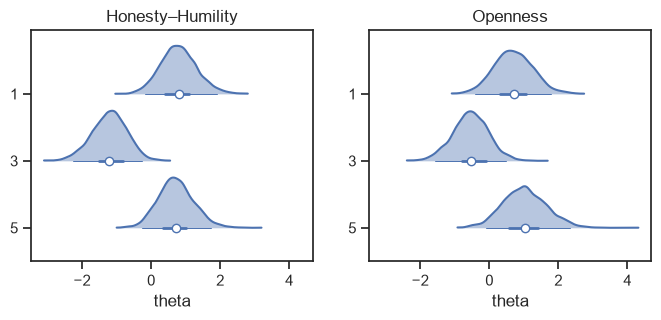

In [11]:
people = model.idata["posterior"]["theta"].person.values[:3].tolist()
trait_names = ["Honesty–Humility", "Openness"]
fc.plot_ridge(
    model.idata,
    coords={"person": people, "trait": ["honestyhumility", "openness"]},
    max_rows=3,
    col_wrap=2,
    figsize=(8, 3),
)
for ax, trait in zip(plt.gcf().axes, trait_names, strict=False):
    ax.set_title(trait)
plt.show()

Compare with [TIRT](tirt_workflow.ipynb), which fits individual comparisons
from the same questionnaire. Its likelihood factors are comparisons, while
TIRTRank's factors are block responses.